In [4]:
import ee
import geopandas as gpd
import pandas as pd
from pathlib import Path

PROCESSED = Path("../data/processed")
EE_PROJECT = "fourth-carport-512220-f2"

In [5]:
ee.Initialize(project=EE_PROJECT)
ee.Number(1).add(1).getInfo()

2

In [6]:
sectors = gpd.read_file(PROCESSED / "sectors_income.gpkg")
sectors.shape   # (2310, 16)

(2310, 16)

#### Transformando malha para longitude e latitude para o Earth Engine

In [7]:
sectors_wgs84 = sectors.to_crs("EPSG:4326")
goiania_geometry = sectors_wgs84.geometry.union_all()

In [8]:
roi = ee.Geometry(goiania_geometry.__geo_interface__)


In [9]:
landsat_8 = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
landsat_9 = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")

In [10]:
landsat = landsat_8.merge(landsat_9)
landsat_period = (
    landsat
    .filterBounds(roi)
    .filterDate("2026-08-01", "2026-10-01")
)

print("Scenes found:", landsat_period.size().getInfo())

Scenes found: 16


In [11]:
scene_features = landsat_period.map(
    lambda image: ee.Feature(
        None,
        {
            "date": ee.Date(image.get("system:time_start")).format("YYYY-MM-dd"),
            "satellite": image.get("SPACECRAFT_ID"),
            "cloud_cover_pct": image.get("CLOUD_COVER"),
            "product_id": image.get("LANDSAT_PRODUCT_ID"),
        },
    )
).getInfo()

scene_table = pd.DataFrame(
    [feature["properties"] for feature in scene_features["features"]]
).sort_values("date")

scene_table

,cloud_cover_pct,date,product_id,satellite
8,0.01,2026-08-01,LC09_L2SP_222071_20260801_20260802_02_T1,LANDSAT_9
12,0.00,2026-08-01,LC09_L2SP_222072_20260801_20260802_02_T1,LANDSAT_9
0,0.64,2026-08-09,LC08_L2SP_222071_20260809_20260816_02_T1,LANDSAT_8
4,40.44,2026-08-09,LC08_L2SP_222072_20260809_20260816_02_T1,LANDSAT_8
9,0.00,2026-08-17,LC09_L2SP_222071_20260817_20260818_02_T1,LANDSAT_9
13,0.00,2026-08-17,LC09_L2SP_222072_20260817_20260818_02_T1,LANDSAT_9
1,37.23,2026-08-25,LC08_L2SP_222071_20260825_20260903_02_T1,LANDSAT_8
5,31.59,2026-08-25,LC08_L2SP_222072_20260825_20260903_02_T1,LANDSAT_8
10,84.47,2026-09-02,LC09_L2SP_222071_20260902_20260903_02_T1,LANDSAT_9
14,64.65,2026-09-02,LC09_L2SP_222072_20260902_20260903_02_T1,LANDSAT_9


In [12]:
def add_local_cloud_stats(image):
    qa = image.select("QA_PIXEL")

    # Bit 0 marks pixels with no valid observation (fill).
    valid = qa.bitwiseAnd(1 << 0).eq(0)

    # Bits 1–4 mark dilated cloud, cirrus, cloud, or cloud shadow.
    cloudy = (
        qa.bitwiseAnd(1 << 1).neq(0)
        .Or(qa.bitwiseAnd(1 << 2).neq(0))
        .Or(qa.bitwiseAnd(1 << 3).neq(0))
        .Or(qa.bitwiseAnd(1 << 4).neq(0))
        .And(valid)
    )

    pixel_flags = (
        valid.rename("valid_px")
        .addBands(cloudy.rename("cloudy_px"))
    )

    stats = pixel_flags.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi,
        scale=30,
        maxPixels=1e8,
        tileScale=4,
    )

    return ee.Feature(
        None,
        {
            "date": image.date().format("YYYY-MM-dd"),
            "satellite": image.get("SPACECRAFT_ID"),
            "scene_cloud_pct": image.get("CLOUD_COVER"),
            "valid_px": stats.get("valid_px"),
            "cloudy_px": stats.get("cloudy_px"),
            "product_id": image.get("LANDSAT_PRODUCT_ID"),
        },
    )

local_features = landsat_period.map(add_local_cloud_stats).getInfo()

local_table = pd.DataFrame(
    [feature["properties"] for feature in local_features["features"]]
)

local_table["goiania_cloud_pct"] = (
    100 * local_table["cloudy_px"] / local_table["valid_px"]
)

local_table[
    ["date", "satellite", "scene_cloud_pct", "goiania_cloud_pct", "product_id"]
].sort_values("date")

,date,satellite,scene_cloud_pct,goiania_cloud_pct,product_id
8,2026-08-01,LANDSAT_9,0.01,0.128255,LC09_L2SP_222071_20260801_20260802_02_T1
12,2026-08-01,LANDSAT_9,0.00,0.180103,LC09_L2SP_222072_20260801_20260802_02_T1
0,2026-08-09,LANDSAT_8,0.64,0.929770,LC08_L2SP_222071_20260809_20260816_02_T1
4,2026-08-09,LANDSAT_8,40.44,0.002614,LC08_L2SP_222072_20260809_20260816_02_T1
9,2026-08-17,LANDSAT_9,0.00,0.003209,LC09_L2SP_222071_20260817_20260818_02_T1
13,2026-08-17,LANDSAT_9,0.00,0.004355,LC09_L2SP_222072_20260817_20260818_02_T1
1,2026-08-25,LANDSAT_8,37.23,99.812293,LC08_L2SP_222071_20260825_20260903_02_T1
5,2026-08-25,LANDSAT_8,31.59,98.628830,LC08_L2SP_222072_20260825_20260903_02_T1
10,2026-09-02,LANDSAT_9,84.47,93.841933,LC09_L2SP_222071_20260902_20260903_02_T1
14,2026-09-02,LANDSAT_9,64.65,95.279807,LC09_L2SP_222072_20260902_20260903_02_T1


In [13]:
def add_thermal_coverage_stats(image):
    qa = image.select("QA_PIXEL")

    # Exclude fill pixels and water from the land-area denominator.
    observed_land = (
        qa.bitwiseAnd(1 << 0).eq(0)
        .And(qa.bitwiseAnd(1 << 7).eq(0))
    )

    # Exclude dilated cloud, cirrus, cloud, and cloud shadow.
    cloud_or_shadow = (
        qa.bitwiseAnd(1 << 1).neq(0)
        .Or(qa.bitwiseAnd(1 << 2).neq(0))
        .Or(qa.bitwiseAnd(1 << 3).neq(0))
        .Or(qa.bitwiseAnd(1 << 4).neq(0))
    )
    clear_land = observed_land.And(cloud_or_shadow.eq(0))

    # ST_B10 is masked where the Landsat surface-temperature product is unavailable.
    st_available = image.select("ST_B10").mask().gt(0)
    valid_thermal = clear_land.And(st_available)

    pixel_flags = (
        observed_land.rename("land_observed_px")
        .addBands(clear_land.rename("clear_land_px"))
        .addBands(valid_thermal.rename("thermal_valid_px"))
    )

    stats = pixel_flags.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi,
        scale=30,
        maxPixels=1e8,
        tileScale=4,
    )

    return ee.Feature(
        None,
        {
            "date": image.date().format("YYYY-MM-dd"),
            "satellite": image.get("SPACECRAFT_ID"),
            "land_observed_px": stats.get("land_observed_px"),
            "clear_land_px": stats.get("clear_land_px"),
            "thermal_valid_px": stats.get("thermal_valid_px"),
            "product_id": image.get("LANDSAT_PRODUCT_ID"),
        },
    )

thermal_features = landsat_period.map(add_thermal_coverage_stats).getInfo()

thermal_scene_table = pd.DataFrame(
    [feature["properties"] for feature in thermal_features["features"]]
)

for column in ["land_observed_px", "clear_land_px", "thermal_valid_px"]:
    thermal_scene_table[column] = pd.to_numeric(thermal_scene_table[column], errors="coerce")

thermal_scene_table["thermal_coverage_pct_land"] = (
    100 * thermal_scene_table["thermal_valid_px"]
    / thermal_scene_table["land_observed_px"]
)
thermal_scene_table["thermal_coverage_pct_clear_land"] = (
    100 * thermal_scene_table["thermal_valid_px"]
    / thermal_scene_table["clear_land_px"]
)

thermal_scene_table[
    [
        "date",
        "satellite",
        "land_observed_px",
        "clear_land_px",
        "thermal_valid_px",
        "thermal_coverage_pct_land",
        "thermal_coverage_pct_clear_land",
        "product_id",
    ]
].sort_values("date")

,date,satellite,land_observed_px,clear_land_px,thermal_valid_px,thermal_coverage_pct_land,thermal_coverage_pct_clear_land,product_id
8,2026-08-01,LANDSAT_9,802920.807843,801881.486275,634806.478431,79.062153,79.164626,LC09_L2SP_222071_20260801_20260802_02_T1
12,2026-08-01,LANDSAT_9,671597.454902,670385.101961,514902.576471,76.668333,76.806984,LC09_L2SP_222072_20260801_20260802_02_T1
0,2026-08-09,LANDSAT_8,802899.341176,795365.427451,627630.172549,78.170468,78.910920,LC08_L2SP_222071_20260809_20260816_02_T1
4,2026-08-09,LANDSAT_8,686888.160784,686870.160784,528136.882353,76.888337,76.890352,LC08_L2SP_222072_20260809_20260816_02_T1
9,2026-08-17,LANDSAT_9,803169.129412,803143.129412,635380.282353,79.109151,79.111712,LC09_L2SP_222071_20260817_20260818_02_T1
13,2026-08-17,LANDSAT_9,687394.960784,687364.960784,528652.682353,76.906686,76.910042,LC09_L2SP_222072_20260817_20260818_02_T1
1,2026-08-25,LANDSAT_8,810338.066667,1521.058824,0.000000,0.000000,0.000000,LC08_L2SP_222071_20260825_20260903_02_T1
5,2026-08-25,LANDSAT_8,688149.149020,9435.694118,3883.854902,0.564391,41.161306,LC08_L2SP_222072_20260825_20260903_02_T1
10,2026-09-02,LANDSAT_9,810325.078431,49873.145098,28728.815686,3.545345,57.603778,LC09_L2SP_222071_20260902_20260903_02_T1
14,2026-09-02,LANDSAT_9,686058.254902,32350.878431,16704.000000,2.434779,51.633838,LC09_L2SP_222072_20260902_20260903_02_T1


In [14]:
def prepare_landsat_image(image):
    qa = image.select("QA_PIXEL")
    excluded_qa_bits = (1 << 0) | (1 << 1) | (1 << 2) | (1 << 3) | (1 << 4) | (1 << 7)
    clear_land = qa.bitwiseAnd(excluded_qa_bits).eq(0)

    # Mask saturated red and near-infrared pixels before calculating NDVI.
    qa_radsat = image.select("QA_RADSAT")
    red_nir_saturation_bits = (1 << 3) | (1 << 4)
    valid_reflectance = clear_land.And(
        qa_radsat.bitwiseAnd(red_nir_saturation_bits).eq(0)
    )

    # Convert stored surface reflectance values to physical reflectance.
    red = image.select("SR_B4").multiply(0.0000275).add(-0.2)
    nir = image.select("SR_B5").multiply(0.0000275).add(-0.2)
    # Negative corrected reflectance can produce NDVI values outside [-1, 1].
    valid_reflectance = valid_reflectance.And(red.gte(0)).And(nir.gte(0))
    ndvi = (
        nir.subtract(red)
        .divide(nir.add(red))
        .rename("ndvi")
        .updateMask(valid_reflectance)
        .updateMask(nir.add(red).neq(0))
    )

    # Convert ST_B10 from its stored value to Kelvin, then to Celsius.
    lst_c = (
        image.select("ST_B10")
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("lst_c")
        .updateMask(clear_land)
    )

    return lst_c.addBands(ndvi).copyProperties(
        image, ["system:time_start", "SPACECRAFT_ID", "LANDSAT_PRODUCT_ID"]
    )

landsat_prepared = landsat_period.map(prepare_landsat_image)

print("Prepared scenes:", landsat_prepared.size().getInfo())
print("Output bands:", landsat_prepared.first().bandNames().getInfo())

Prepared scenes: 16
Output bands: ['lst_c', 'ndvi']


In [15]:
# Group adjacent scene tiles from the same date into one daily observation.
acquisition_dates = ee.List(
    landsat_prepared.aggregate_array("system:time_start")
).map(lambda timestamp: ee.Date(timestamp).format("YYYY-MM-dd")).distinct()

def mosaic_acquisition_date(date_string):
    date = ee.Date(date_string)
    same_day = landsat_prepared.filterDate(date, date.advance(1, "day"))
    return same_day.mosaic().set("system:time_start", date.millis())

daily_landsat = ee.ImageCollection.fromImages(
    acquisition_dates.map(mosaic_acquisition_date)
).sort("system:time_start")

print("Unique acquisition dates:", daily_landsat.size().getInfo())

# Calculate per-pixel medians and retain the number of valid dates per band.
median_bands = daily_landsat.median().clip(roi)
lst_valid_dates = (
    daily_landsat.select("lst_c").count().rename("lst_valid_dates").clip(roi)
)
ndvi_valid_dates = (
    daily_landsat.select("ndvi").count().rename("ndvi_valid_dates").clip(roi)
)
landsat_composite = median_bands.addBands(lst_valid_dates).addBands(ndvi_valid_dates)

composite_summary = landsat_composite.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=30,
    maxPixels=1e8,
    tileScale=4,
).getInfo()

print("Composite bands:", landsat_composite.bandNames().getInfo())
pd.Series(composite_summary, name="min_or_max")

Unique acquisition dates: 8
Composite bands: ['lst_c', 'ndvi', 'lst_valid_dates', 'ndvi_valid_dates']


lst_c_max               48.220749
lst_c_min               16.204155
lst_valid_dates_max      7.000000
lst_valid_dates_min      1.000000
ndvi_max                 0.910371
ndvi_min                -0.130626
ndvi_valid_dates_max     8.000000
ndvi_valid_dates_min     1.000000
Name: min_or_max, dtype: float64

In [16]:
from IPython.display import Image, display

ndvi_visualization = {
    "min": -0.2,
    "max": 0.9,
    "palette": ["#8c510a", "#d8b365", "#f6e8c3", "#a6dba0", "#1b7837"],
}

ndvi_thumbnail_url = landsat_composite.select("ndvi").getThumbURL(
    {
        **ndvi_visualization,
        "region": roi,
        "dimensions": 1000,
        "format": "png",
    }
)

display(Image(url=ndvi_thumbnail_url))

In [17]:
import geemap

sector_fc = geemap.gdf_to_ee(
    sectors_wgs84[["sector_id", "geometry"]]
)

def summarize_sector(feature):
    statistics = landsat_composite.select([
        "lst_c",
        "ndvi",
        "lst_valid_dates",
        "ndvi_valid_dates",
    ]).reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=feature.geometry(),
        scale=30,
        maxPixels=1e8,
        tileScale=4,
    )

    return feature.set(statistics)

sector_metrics = sector_fc.map(summarize_sector)
sector_metrics_gdf = geemap.ee_to_gdf(sector_metrics)

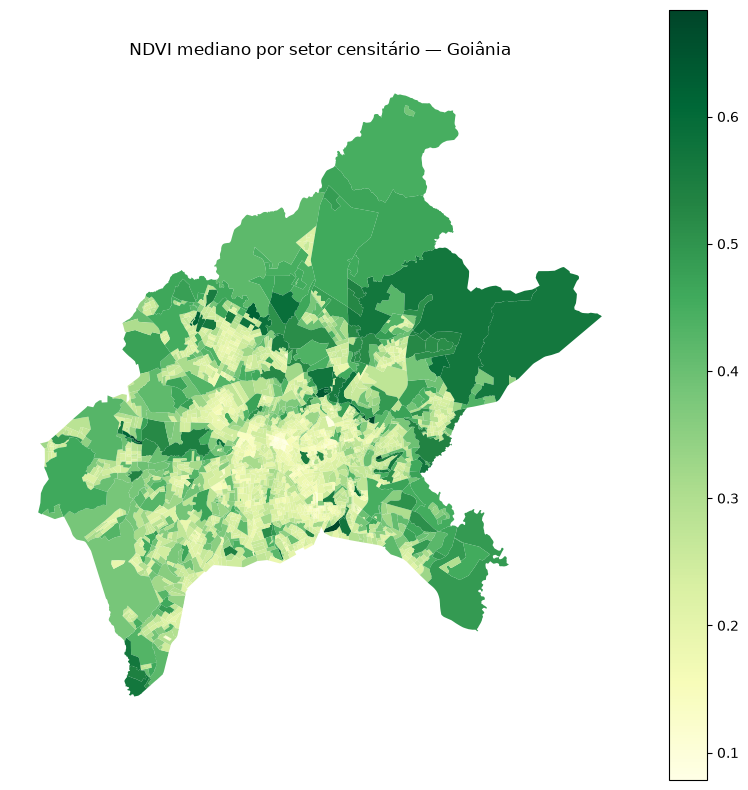

In [19]:
import matplotlib.pyplot as plt

sector_metrics_gdf.plot(
    column="ndvi",
    cmap="YlGn",
    legend=True,
    figsize=(10, 10),
    missing_kwds={"color": "lightgrey", "label": "Sem dado"},
)

plt.title("NDVI mediano por setor censitário — Goiânia")
plt.axis("off")
plt.show()

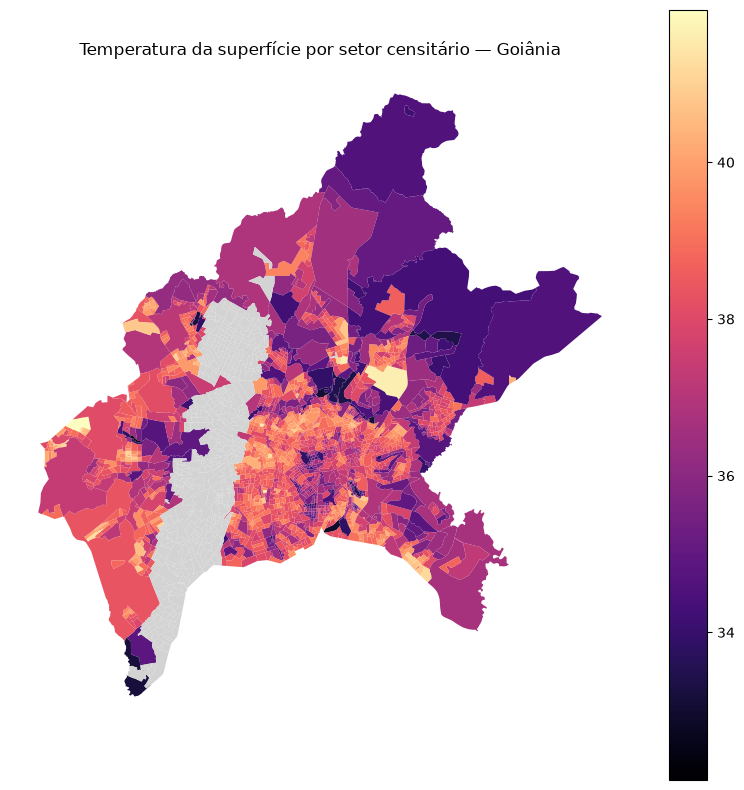

In [20]:
sector_metrics_gdf.plot(
    column="lst_c",
    cmap="magma",
    legend=True,
    figsize=(10, 10),
    missing_kwds={"color": "lightgrey", "label": "Sem dado"},
)

plt.title("Temperatura da superfície por setor censitário — Goiânia")
plt.axis("off")
plt.show()